<a href="https://colab.research.google.com/github/gibranfp/CursoAprendizajeProfundo/blob/2027-1/notebooks/4a_traduccion_atencion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Traducción automática con redes recurrentes y atención
En esta libreta entrenaremos y evaluaremos un traductor automático basado en celdas _long short-term memory_ (LSTM) con el mecanismo de atención de Luong.

In [1]:
from collections.abc import Callable

import copy
import requests
import gzip

import numpy as np
import matplotlib.pyplot as plt

import spacy
from collections import Counter

import torch as th
from torch import nn

from torch.nn.utils.rnn import pad_sequence
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence
from torch.utils.data import Dataset, DataLoader

from torch.utils.tensorboard import SummaryWriter

try:
  import torchmetrics
except ImportError:
  %pip install torchmetrics -qq
  import torchmetrics

DEVICE = 'cuda:0' if th.cuda.is_available() else 'cpu'
EMBED_DIM = 128
HIDDEN_DIM = 64
N_LAYERS = 2
P_DROPOUT = 0.7

BATCH_SIZE = 64
N_EPOCAS = 100
F_GEN = 5

np.random.seed(42)
th.random.manual_seed(42)

## Conjunto de datos Multi30k
Definimos una función para descargar los archivos `.gz` del conjunto de datos Multi30k a partir de la URL:

In [2]:
def download_from_url(url: str,
                      fname: str) -> None:
  with open(fname, 'wb') as f:
    res = requests.get(url)
    res.raise_for_status()
    f.write(res.content)

Descargamos los archivos de entrenamiento, validación y prueba para los idiomas fuente y objetivo:

In [3]:
url_base = 'https://raw.githubusercontent.com/multi30k/dataset/master/data/task1/raw/'
train_urls = ('train.fr.gz', 'train.en.gz')
val_urls = ('val.fr.gz', 'val.en.gz')
test_urls = ('test_2016_flickr.fr.gz', 'test_2016_flickr.en.gz')

download_from_url(url_base + train_urls[0], train_urls[0])
download_from_url(url_base + train_urls[1], train_urls[1])

download_from_url(url_base + val_urls[0], val_urls[0])
download_from_url(url_base + val_urls[1], val_urls[1])

download_from_url(url_base + test_urls[0], test_urls[0])
download_from_url(url_base + test_urls[1], test_urls[1])

Cargamos los analizadores léxicos (_tokenizadores_) de la biblioteca [spaCy](https://spacy.io/) para el idioma fuente y el idioma objetivo:

In [4]:
!python -m spacy download fr_core_news_sm
!python -m spacy download en_core_web_sm

tok_fr = spacy.load("fr_core_news_sm")
tok_en = spacy.load("en_core_web_sm")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.3/16.3 MB 50.4 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('fr_core_news_sm')
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 53.8 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')


El conjunto de datos consiste en archivos comprimidos de texto con una línea por oración. Las líneas del archivo del idioma fuente y del idioma objetivo están emparejadas (es decir, una línea específica contiene la misma oración en cada idioma).

Leemos la primera línea de los archivos de los idiomas fuente y objetivo y las pasamos por el analizador léxico:

In [5]:
with gzip.open(train_urls[0], 'rt', encoding='utf-8') as f:
  txt_fr = f.readline()

with gzip.open(train_urls[1], 'rt', encoding='utf-8') as f:
  txt_en = f.readline()

print(f'Francés: {txt_fr} --> {[t.text for t in tok_fr(txt_fr)]}')
print(f'Inglés: {txt_en} --> {[t.text for t in tok_en(txt_en)]}')

Francés: Deux jeunes hommes blancs sont dehors près de buissons.
 --> ['Deux', 'jeunes', 'hommes', 'blancs', 'sont', 'dehors', 'près', 'de', 'buissons', '.', '\n']
Inglés: Two young, White males are outside near many bushes.
 --> ['Two', 'young', ',', 'White', 'males', 'are', 'outside', 'near', 'many', 'bushes', '.', '\n']


Definimos una función para cargar todas las líneas de un archivo en memoria:

In [6]:
def read_sentences(filepath: str) -> list[str]:
  with gzip.open(filepath, 'rt', encoding='utf-8') as f:
    return f.readlines()

Cargamos las líneas procesadas por el analizador léxico de los archivos de los idiomas fuente y objetivo:

In [7]:
sentences_fr = [[t.text for t in tok_fr(l.strip())] for l in read_sentences(train_urls[0])]
sentences_en = [[t.text for t in tok_en(l.strip())] for l in read_sentences(train_urls[1])]

Definimos una clase y función para construir el vocabulario.

In [8]:
def build_vocab(sentences: list[list[str]]) -> Counter:
  return Counter([t for s in sentences for t in s])

class VocabFrEn:
  def __init__(self,
               sentences_fr: list[list[str]],
               sentences_en: list[list[str]],
               specials: tuple[str, ...] = ('<PAD>', '<CLS>', '<SEP>', '<OOV>'),
               min_freq: int = 2) -> None:
    offset = len(specials)

    # Construimos el vocabulario con los tokens que ocurren al menos min_freq
    # veces en el conjunto de entrenamiento. Los que ocurren menos veces se
    # asignan al token especial <OOV>, de modo que su embedding también se entrena
    vocab_fr = [s for s, f in build_vocab(sentences_fr).most_common() if f >= min_freq]
    vocab_en = [s for s, f in build_vocab(sentences_en).most_common() if f >= min_freq]

    self.id2str_fr = {i+offset:s for i,s in enumerate(vocab_fr)}
    self.str2id_fr = {s:i+offset for i,s in enumerate(vocab_fr)}

    self.id2str_en = {i+offset:s for i,s in enumerate(vocab_en)}
    self.str2id_en = {s:i+offset for i,s in enumerate(vocab_en)}

    for i,s in enumerate(specials):
      self.str2id_fr[s] = i
      self.id2str_fr[i] = s
      self.str2id_en[s] = i
      self.id2str_en[i] = s

Instanciamos el vocabulario y extraemos el índice del _token_ de relleno `<PAD>` para cada idioma.

In [9]:
vocab = VocabFrEn(sentences_fr, sentences_en)
SRC_PAD_IDX = vocab.str2id_fr['<PAD>']
TGT_PAD_IDX = vocab.str2id_en['<PAD>']

Creamos la clase que define el iterable del conjunto de datos Multi30k.

In [10]:
class Multi30k(Dataset):
  def __init__(self,
               path_fr: str,
               path_en: str,
               tok_fr: spacy.language.Language,
               tok_en: spacy.language.Language,
               vocab: VocabFrEn) -> None:
    self.tok_fr = tok_fr
    self.tok_en = tok_en
    self.vocab = vocab

    self.sentences_fr = []
    self.sentences_en = []

    clsid_fr = vocab.str2id_fr['<CLS>']
    sepid_fr = vocab.str2id_fr['<SEP>']
    oovid_fr = vocab.str2id_fr['<OOV>']
    clsid_en = vocab.str2id_en['<CLS>']
    sepid_en = vocab.str2id_en['<SEP>']
    oovid_en = vocab.str2id_en['<OOV>']
    for sfr,sen in zip(read_sentences(path_fr), read_sentences(path_en)):
      sent_fr = [vocab.str2id_fr.get(t.text, oovid_fr) for t in tok_fr(sfr.strip())]
      sent_fr.insert(0, clsid_fr)
      sent_fr.append(sepid_fr)
      self.sentences_fr.append(th.tensor(sent_fr))

      sent_en = [vocab.str2id_en.get(t.text, oovid_en) for t in tok_en(sen.strip())]
      sent_en.insert(0, clsid_en)
      sent_en.append(sepid_en)
      self.sentences_en.append(th.tensor(sent_en))

  def __getitem__(self,
                  idx: int) -> tuple[th.Tensor, th.Tensor]:
    return self.sentences_fr[idx], self.sentences_en[idx]

  def __len__(self) -> int:
    return len(self.sentences_fr)

Instanciamos la clase para los subconjuntos de entrenamiento y validación.

In [11]:
entds = Multi30k(train_urls[0], train_urls[1], tok_fr, tok_en, vocab)
valds = Multi30k(val_urls[0], val_urls[1], tok_fr, tok_en, vocab)

Tomamos un elemento del iterable del subconjunto de entrenamiento.

In [12]:
it = iter(entds)
src, tgt = next(it)
src, tgt

(tensor([   1,   25,   84,   33,  224,   30,   90,   74,    8, 1192,    4,    2]),
 tensor([   1,   19,   25,   15, 1165,  804,   17,   57,   84,  334, 1329,    5,
            2]))

Definimos una función para convertir secuencias de índices a cadenas de caracteres.

In [13]:
def convert_indexes(ten: th.Tensor,
                    id2str: dict) -> list[str]:
  return [id2str[idx.item()] for idx in ten]

print(convert_indexes(src, vocab.id2str_fr))
print(convert_indexes(tgt, vocab.id2str_en))

['<CLS>', 'Deux', 'jeunes', 'hommes', 'blancs', 'sont', 'dehors', 'près', 'de', 'buissons', '.', '<SEP>']
['<CLS>', 'Two', 'young', ',', 'White', 'males', 'are', 'outside', 'near', 'many', 'bushes', '.', '<SEP>']


Definimos una clase para agregar _padding_ a las secuencias y para crear, a partir de la oración objetivo, la secuencia de entrada del decodificador (_teacher forcing_) y la secuencia de salida deseada.

In [14]:
class PadSequences:
  def __call__(self,
               batch: th.Tensor) -> tuple[th.Tensor, th.Tensor, th.Tensor, th.Tensor]:
    # Secuencia de idioma fuente que se usará como entrada para el codificador:
    # <CLS> w1 ... wn <SEP>
    src = [item[0] for item in batch]
    src_len = th.tensor([len(s) for s in src])
    src = pad_sequence(src,
                       batch_first=False,
                       padding_value=SRC_PAD_IDX)

    # Secuencia de idioma objetivo que se usará como salida deseada,
    # quitando <CLS>: w1 ... wn <SEP>
    tgt_out = [item[1][1:] for item in batch]
    tgt_out = pad_sequence(tgt_out,
                           batch_first=False,
                           padding_value=TGT_PAD_IDX)

    # Secuencia de idioma objetivo que se usará como entrada para el teacher forcing,
    # quitando <SEP>: <CLS> w1 ... wn
    tgt_inp = [item[1][:-1] for item in batch]
    tgt_inp = pad_sequence(tgt_inp,
                           batch_first=False,
                           padding_value=TGT_PAD_IDX)

    return src, src_len, tgt_inp, tgt_out

Formamos los cargadores de datos.

In [15]:
entdl = DataLoader(entds,
                   batch_size=BATCH_SIZE,
                   shuffle=True,
                   drop_last=True,
                   collate_fn=PadSequences())

valdl = DataLoader(valds,
                   batch_size=BATCH_SIZE,
                   shuffle=False,
                   drop_last=False,
                   collate_fn=PadSequences())

itdl = iter(entdl)
src_batch, src_len, tgt_inp_batch, tgt_out_batch = next(itdl)
src_batch = src_batch.to(DEVICE)
tgt_inp_batch = tgt_inp_batch.to(DEVICE)
tgt_out_batch = tgt_out_batch.to(DEVICE)

## Arquitectura
La red neuronal tiene una arquitectura codificador-decodificador y está basada en celdas LSTM (_Long Short-Term Memory_).

### Codificador
El codificador espera como entrada una secuencia de índices $(x_c^{[1]}, \ldots, x_c^{[T_c]})$ de longitud $T_c$ que representa una oración en el idioma fuente, la cual convierte a una secuencia de vectores densos $(\mathbf{e}_c^{[1]}, \ldots, \mathbf{e}_c^{[T_c]})$ usando una matriz entrenable (_embedding_). Dicha secuencia se procesa con una o varias celdas LSTM, obteniendo como resultado una secuencia de vectores de estado $(\mathbf{h}_c^{[1]}, \ldots, \mathbf{h}_c^{[T_c]})$, así como los últimos estados $\mathbf{h}_c^{[T_c]}$ y $\mathbf{C}_c^{[T_c]}$. Aquí, $x_c^{[i]} \in \mathbb{N}$, $\mathbf{e}_c^{[i]} \in \mathbb{R}^{D_{cod}}$ y $\mathbf{h}_c^{[i]} \in \mathbb{R}^{L_{cod}}$.

In [16]:
class Encoder(nn.Module):
  def __init__(self,
               vocab_dim: int,
               embed_dim: int,
               hidden_dim: int,
               n_layers: int,
               p_dropout: float = 0,
               pad_idx: int = 0) -> None:
    super(Encoder, self).__init__()

    self.hidden_dim = hidden_dim
    self.n_layers = n_layers
    self.pad_idx = pad_idx

    self.embed = nn.Embedding(vocab_dim, embed_dim, padding_idx = pad_idx)
    self.cells = nn.LSTM(embed_dim,
                         hidden_dim,
                         n_layers,
                         dropout = p_dropout)

  def forward(self,
              x: th.Tensor,
              lengths: th.Tensor) -> tuple[th.Tensor, tuple[th.Tensor, th.Tensor]]:
    # [n_steps, n_examples] -> [n_steps, n_examples, embed_dim]
    embs = self.embed(x)

    packed = pack_padded_sequence(embs, lengths.cpu(), enforce_sorted=False)

    # output: [n_steps, n_examples, hidden_dim]
    # h,c: [n_layers, n_examples, hidden_dim]
    output, (h, c) = self.cells(packed)
    output, _ = pad_packed_sequence(output, total_length=x.shape[0])

    return output, (h, c)

enc = Encoder(len(vocab.str2id_fr),
              EMBED_DIM,
              HIDDEN_DIM,
              N_LAYERS,
              P_DROPOUT,
              vocab.str2id_fr['<PAD>'])
enc.to(DEVICE)
enc_outputs, (h, c) = enc(src_batch, src_len)
print(enc_outputs, (h, c))

tensor([[[ 4.7688e-02,  3.3575e-02,  5.6824e-02,  ...,  3.0997e-02,
           1.2987e-02,  7.3221e-03],
         [-8.8707e-03,  5.1764e-02,  3.5792e-02,  ..., -5.2652e-02,
          -1.7575e-02, -8.0503e-02],
         [-2.6827e-02,  5.3097e-03, -2.3822e-02,  ..., -5.3716e-02,
          -3.1104e-06, -5.6029e-02],
         ...,
         [-6.0829e-02, -1.4788e-02,  5.3022e-02,  ..., -3.8796e-02,
          -4.5954e-02, -1.4184e-02],
         [-3.3048e-02, -1.2104e-02,  2.6612e-02,  ..., -7.1099e-02,
           1.5398e-02, -2.6463e-02],
         [-2.6362e-03, -2.8253e-02, -9.9155e-03,  ..., -7.5474e-02,
          -1.4334e-02,  2.8039e-02]],

        [[-7.9794e-02,  2.6504e-02,  1.0106e-01,  ...,  3.1352e-02,
          -1.2544e-02, -2.6076e-02],
         [ 7.5715e-02, -8.3730e-02, -1.6295e-02,  ..., -1.3175e-01,
           2.2317e-02, -6.9189e-02],
         [-4.0578e-02, -1.7038e-02,  7.7918e-03,  ..., -8.6208e-02,
          -4.2491e-02, -4.7537e-02],
         ...,
         [-4.1109e-02,  1

### Decodificador
El decodificador recibe como estado inicial los últimos estados del codificador, $\mathbf{h}_d^{[0]} = \mathbf{h}_c^{[T_c]}$ y $\mathbf{C}_d^{[0]} = \mathbf{C}_c^{[T_c]}$ (con varias capas, el último estado de cada capa del codificador inicializa la capa correspondiente del decodificador), y una secuencia de índices $(x_d^{[1]}, \ldots, x_d^{[T_d]})$ de longitud $T_d$ que comienza con el _token_ `<CLS>`. Esta secuencia se convierte a una secuencia de vectores densos $(\mathbf{e}_d^{[1]}, \ldots, \mathbf{e}_d^{[T_d]})$ usando una matriz entrenable (_embedding_) y se procesa con una o varias capas LSTM, obteniendo como resultado una secuencia de vectores de estado $(\mathbf{h}_d^{[1]}, \ldots, \mathbf{h}_d^{[T_d]})$, así como los últimos estados $\mathbf{h}_d^{[T_d]}$ y $\mathbf{C}_d^{[T_d]}$. Aquí, $x_d^{[i]} \in \mathbb{N}$, $\mathbf{e}_d^{[i]} \in \mathbb{R}^{D_{dec}}$ y $\mathbf{h}_d^{[i]} \in \mathbb{R}^{L_{dec}}$, con $L_{dec} = L_{cod}$ para que los estados del codificador puedan usarse como estado inicial.

En un modelo secuencia a secuencia con redes recurrentes sin atención, toda la información de la oración fuente tendría que caber en los últimos estados $\mathbf{h}_c^{[T_c]}$ y $\mathbf{C}_c^{[T_c]}$, lo que limita la calidad de la traducción. Para evitarlo, usamos la atención de Luong: en cada paso $t$, el decodificador consulta todos los estados del codificador $(\mathbf{h}_c^{[1]}, \ldots, \mathbf{h}_c^{[T_c]})$ y se enfoca en los más relevantes para predecir la siguiente palabra. Primero, calculamos una puntuación entre el estado $\mathbf{h}_d^{[t]}$ y cada estado del codificador, normalizándola con la función $\operatorname{softmax}$:

$$
\begin{align*}
  s_{t,s} &= \mathbf{h}_d^{[t]\top} \mathbf{W}_a\, \mathbf{h}_c^{[s]}\\
  \alpha_{t,s} &= \frac{\exp(s_{t,s})}{\sum_{s'=1}^{T_c} \exp(s_{t,s'})}
\end{align*}
$$

donde $\mathbf{W}_a \in \mathbb{R}^{L_{dec} \times L_{cod}}$ es una matriz entrenable. Los pesos de atención $\alpha_{t,s}$ son no negativos y suman 1 sobre las posiciones $s$ de la oración fuente. El vector de contexto se calcula como un promedio ponderado de los estados del codificador:

$$
\mathbf{c}^{[t]} = \sum_{s=1}^{T_c} \alpha_{t,s}\, \mathbf{h}_c^{[s]}
$$

Las posiciones de relleno `<PAD>` de la oración fuente se excluyen asignándoles una puntuación de $-\infty$ antes de la $\operatorname{softmax}$, de modo que su peso es cero.

Posteriormente, combinamos el vector de contexto con el estado del decodificador para obtener el estado con atención:

$$
\tilde{\mathbf{h}}^{[t]} = \tanh\left(\mathbf{W}_c\left[\mathbf{c}^{[t]}; \mathbf{h}_d^{[t]}\right]\right),
$$

donde $\mathbf{W}_c \in \mathbb{R}^{L_{dec} \times 2L_{dec}}$ es una matriz entrenable. Este vector se alimenta a una capa densa para obtener los _logits_ $\mathbf{o}^{[t]} = \mathbf{W}_y\tilde{\mathbf{h}}^{[t]} + \mathbf{b}_y \in \mathbb{R}^{|\mathcal{V}_{obj}|}$, donde $|\mathcal{V}_{obj}|$ es el tamaño del vocabulario del idioma objetivo. Al aplicar la función $\operatorname{softmax}$ a $\mathbf{o}^{[t]}$ se obtiene la distribución de probabilidad de la siguiente palabra $x_d^{[t+1]}$.

Como la atención se calcula después de las capas LSTM, durante el entrenamiento con _teacher forcing_ todos los pasos del decodificador pueden procesarse en una sola llamada.

In [17]:
class AtencionLuong(nn.Module):
  def __init__(self, hidden_dim: int) -> None:
    super(AtencionLuong, self).__init__()
    self.Wa = nn.Linear(hidden_dim, hidden_dim, bias=False)
    self.Wc = nn.Linear(2 * hidden_dim, hidden_dim, bias=False)

  def forward(self,
              dec_out: th.Tensor,
              enc_out: th.Tensor,
              src_mask: th.Tensor) -> tuple[th.Tensor, th.Tensor]:
    # [n_steps, n_examples, hidden_dim] -> [n_examples, n_steps, hidden_dim]
    hd = dec_out.transpose(0, 1)
    he = enc_out.transpose(0, 1)

    # Puntuaciones: [n_examples, n_steps_dec, n_steps_enc]
    s = hd @ self.Wa(he).transpose(1, 2)

    # El relleno de la oración fuente no recibe atención
    s = s.masked_fill(~src_mask.T.unsqueeze(1), -th.inf)
    alfa = th.softmax(s, dim=-1)

    # Vectores de contexto: [n_examples, n_steps_dec, hidden_dim]
    ctx = alfa @ he

    # Concatenamos contexto y estado: [n_steps_dec, n_examples, 2 * hidden_dim]
    ctxhd = th.cat([ctx, hd], dim=-1)

    # Proyectamos el vector concatenado
    h_tilde = th.tanh(self.Wc(ctxhd))

    return h_tilde.transpose(0, 1), alfa

class Decoder(nn.Module):
  def __init__(self,
               vocab_dim: int,
               embed_dim: int,
               hidden_dim: int,
               n_layers: int,
               p_dropout: float = 0,
               pad_idx: int = 0) -> None:
    super(Decoder, self).__init__()

    self.hidden_dim = hidden_dim
    self.n_layers = n_layers
    self.vocab_dim = vocab_dim
    self.pad_idx = pad_idx

    self.embed = nn.Embedding(vocab_dim, embed_dim, padding_idx = pad_idx)
    self.cells = nn.LSTM(embed_dim,
                         hidden_dim,
                         n_layers,
                         dropout = p_dropout)
    self.atencion = AtencionLuong(hidden_dim)
    self.fc = nn.Linear(hidden_dim, vocab_dim)

  def forward(self,
              x: th.Tensor,
              h0: th.Tensor,
              c0: th.Tensor,
              enc_out: th.Tensor,
              src_mask: th.Tensor) -> tuple[th.Tensor, tuple[th.Tensor, th.Tensor]]:
    # [n_steps, n_examples] -> [n_steps, n_examples, embed_dim]
    embs = self.embed(x)

    # output: [n_steps, n_examples, hidden_dim]
    # h y c: [n_layers, n_examples, hidden_dim]
    output, (h, c) = self.cells(embs, (h0, c0))

    h_tilde, alfa = self.atencion(output, enc_out, src_mask)

    # [n_steps, n_examples, hidden_dim] -> [n_steps, n_examples, vocab_dim]
    logits = self.fc(h_tilde)

    return logits, (h, c), alfa

dec = Decoder(len(vocab.str2id_en),
              EMBED_DIM,
              HIDDEN_DIM,
              N_LAYERS,
              P_DROPOUT,
              vocab.str2id_en['<PAD>'])
dec.to(DEVICE)
src_mask = src_batch != vocab.str2id_fr['<PAD>']
l, (h, c), alfa = dec(tgt_inp_batch, h, c, enc_outputs, src_mask)

print(l, (h, c), alfa)

tensor([[[ 0.1181,  0.0188,  0.1345,  ..., -0.0336,  0.0327,  0.0108],
         [ 0.1107,  0.0203,  0.1136,  ..., -0.0439, -0.0008,  0.0230],
         [ 0.1276,  0.0291,  0.1343,  ..., -0.0152,  0.0194,  0.0069],
         ...,
         [ 0.1358,  0.0192,  0.1359,  ..., -0.0207,  0.0027,  0.0062],
         [ 0.1092,  0.0227,  0.1259,  ..., -0.0544,  0.0172,  0.0080],
         [ 0.1168,  0.0234,  0.1189,  ..., -0.0174,  0.0335,  0.0105]],

        [[ 0.1301,  0.0358,  0.1403,  ..., -0.0243,  0.0456,  0.0119],
         [ 0.1049,  0.0249,  0.1127,  ..., -0.0368, -0.0031,  0.0121],
         [ 0.1269,  0.0618,  0.1223,  ..., -0.0276,  0.0416,  0.0124],
         ...,
         [ 0.1187,  0.0289,  0.1157,  ..., -0.0356,  0.0166,  0.0165],
         [ 0.1256,  0.0197,  0.1282,  ..., -0.0283,  0.0237,  0.0013],
         [ 0.1182,  0.0328,  0.1256,  ..., -0.0246,  0.0380,  0.0183]],

        [[ 0.1260,  0.0166,  0.1398,  ..., -0.0188,  0.0433, -0.0022],
         [ 0.0995,  0.0331,  0.1165,  ..., -0

### Secuencia a secuencia
El traductor combina el codificador y el decodificador en una arquitectura secuencia a secuencia. El codificador procesa la oración en el idioma fuente $(x_c^{[1]}, \ldots, x_c^{[T_c]})$ y le pasa al decodificador:
* Sus últimos estados $\mathbf{h}_c^{[T_c]}$ y $\mathbf{C}_c^{[T_c]}$, que se usan como estado inicial del decodificador
* La secuencia completa de estados $(\mathbf{h}_c^{[1]}, \ldots, \mathbf{h}_c^{[T_c]})$, que se usa en la atención, junto con una máscara que indica qué posiciones de la oración fuente corresponden a relleno para que estas no reciban peso.

Durante el entrenamiento usamos _teacher forcing_: en lugar de alimentar al decodificador con sus propias predicciones, le pasamos la oración objetivo correcta desplazada un paso. Si la oración objetivo es `<CLS>` $w_1 \ldots w_n$ `<SEP>`, la entrada del decodificador es `<CLS>` $w_1 \ldots w_n$ y la salida deseada es $w_1 \ldots w_n$ `<SEP>`. De esta forma, en cada paso $t$ el modelo aprende a predecir $x_d^{[t+1]}$ a partir de las palabras correctas anteriores y todos los pasos pueden procesarse en una sola llamada al decodificador. En la inferencia, no conocemos la oración objetivo, por lo que el decodificador debe generar la traducción palabra por palabra.

In [18]:
class Seq2Seq(nn.Module):
  def __init__(self,
               vocab: VocabFrEn,
               embed_dim: int,
               hidden_dim: int,
               n_layers: int,
               p_dropout: float = 0) -> None:
    super(Seq2Seq, self).__init__()

    self.vocab = vocab
    self.src_vocab_dim = len(vocab.str2id_fr)
    self.tgt_vocab_dim = len(vocab.str2id_en)

    self.emb_dim = embed_dim
    self.hidden_dim = hidden_dim
    self.n_layers = n_layers

    self.enc = Encoder(self.src_vocab_dim,
                       embed_dim,
                       hidden_dim,
                       n_layers,
                       p_dropout,
                       self.vocab.str2id_fr['<PAD>'])
    self.dec = Decoder(self.tgt_vocab_dim,
                       embed_dim,
                       hidden_dim,
                       n_layers,
                       p_dropout,
                       self.vocab.str2id_en['<PAD>'])

  def forward(self,
              src: th.Tensor,
              src_len: th.Tensor,
              tgt: th.Tensor) -> th.Tensor:
    enc_out, (he, ce) = self.enc(src, src_len)
    src_mask = src != self.vocab.str2id_fr['<PAD>']
    logits, _, _ = self.dec(tgt, he, ce, enc_out, src_mask)

    return logits

modelo = Seq2Seq(vocab,
                 EMBED_DIM,
                 HIDDEN_DIM,
                 N_LAYERS,
                 P_DROPOUT)
modelo.to(DEVICE)
modelo(src_batch, src_len, tgt_inp_batch)

tensor([[[ 0.0507, -0.0433,  0.0473,  ...,  0.1277, -0.0141,  0.1021],
         [ 0.0831, -0.0562,  0.0644,  ...,  0.1412, -0.0282,  0.1063],
         [ 0.0510, -0.0310,  0.0425,  ...,  0.1045,  0.0050,  0.1051],
         ...,
         [ 0.0687, -0.0329,  0.0467,  ...,  0.1118,  0.0037,  0.1163],
         [ 0.0472, -0.0511,  0.0463,  ...,  0.1127,  0.0011,  0.1009],
         [ 0.0590, -0.0510,  0.0483,  ...,  0.1222, -0.0033,  0.1111]],

        [[ 0.0632, -0.0290,  0.0528,  ...,  0.1135,  0.0075,  0.1065],
         [ 0.0758, -0.0363,  0.0394,  ...,  0.1436, -0.0020,  0.1155],
         [ 0.0649, -0.0214,  0.0298,  ...,  0.1105, -0.0009,  0.1091],
         ...,
         [ 0.0544, -0.0385,  0.0385,  ...,  0.1281, -0.0055,  0.1165],
         [ 0.0510, -0.0331,  0.0376,  ...,  0.1163,  0.0105,  0.1241],
         [ 0.0841, -0.0375,  0.0442,  ...,  0.1220, -0.0115,  0.1160]],

        [[ 0.0526, -0.0442,  0.0545,  ...,  0.1112, -0.0021,  0.1050],
         [ 0.0620, -0.0452,  0.0520,  ...,  0

## Inferencia por búsqueda codiciosa
Creamos una función para generar el idioma objetivo dado el idioma fuente usando el modelo secuencia a secuencia definido anteriormente. Se realiza mediante búsqueda codiciosa (_greedy search_), esto es, se toma la palabra más probable de la salida del decodificador como la siguiente palabra de entrada. Este procedimiento se repite hasta que se tenga el máximo tamaño de secuencia o que la siguiente palabra sea el _token_ especial `<SEP>`.

In [19]:
@th.inference_mode()
def traduce_greedy(modelo: nn.Module,
                   src: th.Tensor,
                   src_len: th.Tensor,
                   vocab: VocabFrEn,
                   t_max: int = 100) -> list[str]:
  # Ponemos el modelo en modo evaluación
  modelo.eval()

  # Obtener el índice del token de fin <SEP>
  sep_idx = vocab.str2id_en['<SEP>']

  # número de oraciones de entrada en el idioma fuente
  n_inp_sent = src.shape[-1]

  # pasamos el texto en el idioma fuente por el codificador
  enc_out, (h, c) = modelo.enc(src, src_len)

  # Máscara para que el relleno de la oración fuente no reciba atención
  src_mask = src != vocab.str2id_fr['<PAD>']

  # creamos un tensor de tamaño igual al número de oraciones de entrada en el
  # idioma fuente con todos los valores igual al token de fin <SEP>
  idxs = th.full((t_max, n_inp_sent),
                  sep_idx,
                  device = src.device,
                  dtype = src.dtype)

  # ponemos valores del primer paso igual al índice del token de inicio <CLS>
  idxs[0] = vocab.str2id_en['<CLS>']

  # Máscara para indicar qué oraciones han terminado de generarse
  terminadas = th.zeros(n_inp_sent, dtype=th.bool, device=src.device)
  for step in range(1, t_max):
    # pasamos lote con últimas palabras y estado anterior del decodificador
    # (último estado del codificador en la primera llamada) para obtener las
    # probabilidades de siguiente palabra
    logits, (h, c), _ = modelo.dec(idxs[step - 1:step], h, c, enc_out, src_mask)

    # tomamos la palabra más probable como siguiente en cada ejemplo del lote
    sig = logits[-1].argmax(axis = 1)

    # las oraciones que ya terminaron siguen generando <SEP>
    idxs[step] = th.where(terminadas, sep_idx, sig)

    # Actualizamos la máscara de oraciones terminadas
    terminadas |= idxs[step] == sep_idx

    # generación termina si todas las siguientes palabras corresponden a <SEP>
    if terminadas.all():
      break

  secuencias = idxs[1:step + 1].T.tolist()
  texts = []
  for s in secuencias:
    if sep_idx in s:
      s = s[:s.index(sep_idx)]

    texts.append(' '.join([vocab.id2str_en[j] for j in s]))

  return texts

Traducimos un lote con el modelo sin entrenar.

In [20]:
traducciones = traduce_greedy(modelo, src_batch, src_len, vocab)
print(traducciones)

['lounge security security security security security security security security security security security security security security security security security security security security security security security security security security security security security security security security security security security security security security security security security security security security security security security security security security security security security security security security security security security security security security security security security security security security security security security security security security security security security security security security security security security security security security security security security security security security security security security security security security', 'cart cart cart lounge security security security security security security security security security sec

### Visualización del mapa de atención
Una ventaja de la atención es que podemos inspeccionar en qué partes de la oración fuente se enfoca el modelo al generar cada palabra. Para ello, definimos una función que traduce una oración y grafica la matriz de pesos de atención $\alpha_{t,s}$ como una imagen. Cada fila corresponde a una palabra generada en el idioma objetivo y cada columna a una palabra de la oración fuente, de modo que la fila $t$ muestra cómo se distribuye la atención sobre la oración fuente al predecir la palabra $t$. Los tonos más oscuros indican pesos mayores.

In [21]:
@th.inference_mode()
def grafica_atencion(modelo, src, src_len, vocab):
  trad = traduce_greedy(modelo, src, src_len, vocab)[0].split()
  tgt = th.tensor([vocab.str2id_en['<CLS>']] +
                  [vocab.str2id_en.get(w, vocab.str2id_en['<OOV>']) for w in trad],
                  device=src.device).unsqueeze(1)

  enc_out, (h, c) = modelo.enc(src, src_len)
  src_mask = src != vocab.str2id_fr['<PAD>']
  _, _, alfa = modelo.dec(tgt, h, c, enc_out, src_mask)

  src_txt = convert_indexes(src[:src_len[0], 0], vocab.id2str_fr)
  tgt_txt = trad + ['<SEP>']

  plt.imshow(alfa[0, :, :src_len[0]].cpu(), cmap='gray_r')
  plt.xticks(range(len(src_txt)), src_txt, rotation=90)
  plt.yticks(range(len(tgt_txt)), tgt_txt[:alfa.shape[1]])
  plt.show()

## Funciones para el entrenamiento
Para facilitar el entrenamiento, definimos diversas funciones.

### Guardar _checkpoint_
Definimos una función para guardar el estado del entrenamiento y del modelo usando la función `save`.

In [22]:
def guarda_ckpt(ckptpath: str,
                modelo: nn.Module,
                epoca: int,
                opt: th.optim.Optimizer) -> None:
  estado_modelo = {'epoch': epoca,
                   'model_state_dict': modelo.state_dict(),
                   'optimizer_state_dict': opt.state_dict()}
  th.save(estado_modelo, ckptpath)

### Registrar información para Tensorboard
Para guardar información que pueda visualizarse con Tensorboard, instanciamos la clase `SummaryWriter` del submódulo `tensorboard` del módulo `utils` y escribimos información mediante los distintos métodos disponibles (por ej. `add_scalar`, `add_image`, `add_histogram`, etc.).

In [23]:
def registra_info_tboard(writer: SummaryWriter,
                         epoca: int,
                         hist: dict[dict]) -> None:
  for (p,vp) in hist.items():
    for (m,vm) in vp.items():
      writer.add_scalar(f'{m}/{p}', vm[epoca], epoca)

### Métrica de exactitud
Como métrica durante el entrenamiento usaremos la exactitud por _token_, sin contar el relleno. Nota que esta métrica se calcula con _teacher forcing_, por lo que tiende a sobreestimar la calidad de las traducciones generadas.

Definimos una clase para calcular la métrica de exactitud lote por lote. Similar a la clase base Metric de la biblioteca TorchMetrics, la clase cuenta con los siguientes métodos:

* `__init__`: Constructor de la clase. Inicializa en cero los acumuladores de aciertos y de ejemplos procesados.
* `update`: Recibe un tensor con los _logits_ de cada ejemplo del lote y paso de tiempo, así como un tensor con los índices de los _tokens_ reales correspondientes. Toma como _token_ predicho el de la puntuación más alta y, sin considerar las posiciones de relleno, acumula el número de coincidencias con los _tokens_ reales y el número de _tokens_ evaluados.
* `compute`: Regresa el cociente entre los aciertos y los _tokens_ acumulados hasta el momento de la llamada.
* `reset`: Vuelve a poner en cero los acumuladores de aciertos y de _tokens_ procesados.



In [24]:
class Exactitud:
  def __init__(self, pad_idx: int, disp: str | th.device = 'cpu') -> None:
    self.disp = disp
    self.pad_idx = pad_idx
    self.reset()

  def update(self, y_hat: th.Tensor, y: th.Tensor) -> None:
    # Posiciones que no corresponden a relleno
    mask = y != self.pad_idx

    # Número de tokens predichos correctamente y número de tokens (sin contar <PAD>)
    self.correcto += (y_hat.argmax(-1)[mask] == y[mask]).sum()
    self.total += mask.sum()

  def compute(self) -> th.Tensor:
    return self.correcto / self.total

  def reset(self) -> None:
    self.correcto = th.zeros((), dtype=th.long, device=self.disp)
    self.total = th.zeros((), dtype=th.long, device=self.disp)

### Paso de entrenamiento
Definimos una función que realiza un paso de entrenamiento, a la cual llamaremos `paso_ent`. Esta función recibe como argumentos:
- El modelo como una instancia de `Module` (`modelo`).
- La función de pérdida (`fp`).
- La métrica a evaluar (`metrica`).
- Una instancia de `Optimizer` del módulo `optim` de PyTorch para actualizar los pesos y sesgos (`opt`).
- Una instancia de `Tensor` con el lote de oraciones en el idioma fuente (`src`).
- Una instancia de `Tensor` con las longitudes del lote de oraciones en el idioma fuente (`src_len`).
- Una instancia de `Tensor` con el lote de entradas del decodificador para el _teacher forcing_ (`tgt_inp`).
- Una instancia de `Tensor` con el lote de salidas deseadas (`tgt_out`).

La función obtiene las predicciones del modelo para las entradas, calcula la pérdida, obtiene los gradientes y actualiza todos los parámetros del modelo mediante el optimizador pasado como argumento.

In [25]:
def paso_ent(modelo: nn.Module,
             fp: Callable,
             metrica: Exactitud,
             opt: th.optim.Optimizer,
             src: th.Tensor,
             src_len: th.Tensor,
             tgt_inp: th.Tensor,
             tgt_out: th.Tensor) -> float:
  # Ponemos los gradientes asociados a los parámetros
  # a actualizar en cero
  opt.zero_grad()

  # Propagamos las entradas para obtener las predicciones
  y_hat = modelo(src, src_len, tgt_inp)

  y_hat = y_hat.reshape(-1, y_hat.shape[-1])
  tgt_out = tgt_out.reshape(-1)

  # Calculamos la pérdida
  perdida = fp(y_hat, tgt_out)

  # Obtenemos los gradientes
  perdida.backward()

  # Limitamos la norma de gradientes
  nn.utils.clip_grad_norm_(modelo.parameters(),
                           max_norm = 1.0)

  # Actualizamos todos los parámetros del modelo
  opt.step()

  # Desconectamos la pérdida del grafo de cómputo
  perdida_paso = perdida.detach()

  # Actualizamos la métrica
  with th.no_grad():
    metrica.update(y_hat, tgt_out)

  return perdida_paso

### Época de entrenamiento
Definimos una función para realizar una época de entrenamiento, que llamaremos `entrena_epoca`. Esta función recibe como argumentos:
- El modelo como una instancia de `Module` (`modelo`).
- La función de pérdida (`fp`).
- La métrica a evaluar (`metrica`).
- Una instancia de `Optimizer` del módulo `optim` de PyTorch para actualizar los pesos y sesgos (`opt`).
- El cargador de datos del subconjunto de entrenamiento (`dl`).
- El dispositivo en el que se ejecutará el modelo (`disp`).

In [26]:
def entrena_epoca(modelo: nn.Module,
                  fp: Callable,
                  metrica: Exactitud,
                  opt: th.optim.Optimizer,
                  dl: th.utils.data.DataLoader,
                  disp: str | th.device = 'cpu') -> tuple[float, float]:
  n_total = 0
  suma_perdida = 0.0
  metrica.reset()

  modelo.train()
  for src,src_len,tgt_inp,tgt_out in dl:
    src = src.to(disp)
    tgt_inp = tgt_inp.to(disp)
    tgt_out = tgt_out.to(disp)

    perdida_paso = paso_ent(modelo,
                            fp,
                            metrica,
                            opt,
                            src,
                            src_len,
                            tgt_inp,
                            tgt_out)

    n_tok = (tgt_out != TGT_PAD_IDX).sum()
    n_total += n_tok

    # Asumiendo que la pérdida tiene reduce='mean'
    suma_perdida += perdida_paso * n_tok

  perdida_epoca = (suma_perdida / n_total).item()
  metrica_epoca = metrica.compute().item()

  return perdida_epoca, metrica_epoca

### Evaluación
Definimos la función evalua para evaluar el modelo en un subconjunto de datos. Esta función recibe como argumentos:

* El modelo como una instancia de `Module` (`modelo`).
* La función de pérdida (`fp`).
* La métrica a evaluar (`metrica`)
* El cargador de datos del subconjunto (`dl`).
* El dispositivo en el que se ejecutará el modelo (`disp`).

In [27]:
@th.inference_mode()
def evalua(modelo: nn.Module,
           fp: Callable,
           metrica: Exactitud,
           dl: DataLoader,
           disp: str | th.device = 'cpu') -> tuple[float, float]:
  n_total = 0
  suma_perdida = 0.0
  metrica.reset()

  modelo.eval()
  for src,src_len,tgt_inp,tgt_out in dl:
    src = src.to(disp)
    tgt_inp = tgt_inp.to(disp)
    tgt_out = tgt_out.to(disp)

    y_hat = modelo(src, src_len, tgt_inp)

    tgt_out = tgt_out.reshape(-1)
    y_hat = y_hat.reshape(-1, y_hat.shape[-1])

    n_tok = (tgt_out != TGT_PAD_IDX).sum()
    n_total += n_tok

    # Asumiendo que la pérdida tiene reduce='mean'
    suma_perdida += fp(y_hat, tgt_out) * n_tok
    metrica.update(y_hat, tgt_out)

  perdida_total = (suma_perdida / n_total).item()
  metrica_total = metrica.compute().item()

  return perdida_total, metrica_total

### Ciclo principal
También definimos el ciclo de entrenamiento principal, que llamaremos `entrena`. Esta función recibe como argumentos:
- El modelo como una instancia de `Module` (`modelo`).
- La función de pérdida (`fp`).
- La métrica a evaluar (`metrica`)
- Una instancia de `Optimizer` del módulo `optim` de PyTorch para actualizar los pesos y sesgos (`opt`).
- El cargador de datos del subconjunto de entrenamiento (`entdl`).
- El cargador de datos del subconjunto de validación (`valdl`).
- El dispositivo en el que se ejecutará el modelo (`disp`).
- La ruta al archivo donde se guardará el estado del entrenamiento y el modelo (`ckptpath`).
- El número de épocas de entrenamiento (`n_epocas`).
- La ruta al directorio donde se guardará la información para Tensorboard (`tbdir`).

En cada época se realiza un paso de entrenamiento por cada lote del subconjunto de entrenamiento y, al final de la época, se calculan la pérdida y la métrica en el subconjunto de validación. Se conserva una copia del modelo con la menor pérdida de validación (`mejor_modelo`).

In [28]:
def entrena(modelo: nn.Module,
            fp: Callable,
            metrica: Exactitud,
            opt: th.optim.Optimizer,
            entdl: th.utils.data.DataLoader,
            valdl: th.utils.data.DataLoader,
            disp: str,
            ckptpath: str | None = None,
            n_epocas = 10,
            freqgen = 5,
            tbdir = 'runs/') -> tuple[nn.Module, nn.Module, dict[dict]]:
  hist = {
    'ent': {
            'perdida': np.zeros(n_epocas),
            "exactitud": np.zeros(n_epocas)
           },
    'val': {
           'perdida': np.zeros(n_epocas),
           "exactitud": np.zeros(n_epocas)
           }
  }

  tbwriter = SummaryWriter(tbdir)
  perdida_min = th.inf

  mejor_modelo = copy.deepcopy(modelo)
  for m in mejor_modelo.modules():
    if isinstance(m, nn.RNNBase):
      m.flatten_parameters()

  # Ejemplo para generar
  src_ej, src_len_ej, _, tgt_ej = next(iter(valdl))
  src_ej = src_ej[:, 0:1].to(disp)
  src_len_ej = src_len_ej[0:1]
  tgt_ej = tgt_ej[:, 0:1].to(disp)

  # Texto del ejemplo en el idioma fuente y objetivo
  tokens_especiales = {'<PAD>', '<CLS>', '<SEP>'}
  src_ej_txt = [t for t in convert_indexes(src_ej, modelo.vocab.id2str_fr)
                if t not in tokens_especiales]
  tgt_ej_txt = [t for t in convert_indexes(tgt_ej, modelo.vocab.id2str_en)
                if t not in tokens_especiales]

  modelo.to(disp)
  for e in range(n_epocas):
    # Bucle de entrenamiento
    hist['ent']['perdida'][e], hist['ent']['exactitud'][e] = entrena_epoca(modelo,
                                                                           fp,
                                                                           metrica,
                                                                           opt,
                                                                           entdl,
                                                                           disp)

    # Bucle de validación
    hist['val']['perdida'][e], hist['val']['exactitud'][e] = evalua(modelo,
                                                                    fp,
                                                                    metrica,
                                                                    valdl,
                                                                    disp)

    # guardamos checkpoint y copiamos pesos y sesgos del modelo
    # actual si disminuye la metrica a monitorear
    if hist['val']['perdida'][e] < perdida_min:
      mejor_modelo.load_state_dict(modelo.state_dict())
      perdida_min = hist['val']['perdida'][e]

      if ckptpath is not None:
        guarda_ckpt(ckptpath, modelo, e, opt)

    registra_info_tboard(tbwriter, e, hist)

    print(f'Época {e}: '
          f'Pérdida(E) = {hist["ent"]["perdida"][e]:.5f}, '
          f'{"exactitud"}(E) = {hist["ent"]["exactitud"][e]:.5f}, '
          f'Pérdida(V) = {hist["val"]["perdida"][e]:.5f}, '
          f'{"exactitud"}(V) = {hist["val"]["exactitud"][e]:.5f}')

    if e % freqgen == 0:
      traduccion = traduce_greedy(modelo, src_ej, src_len_ej, modelo.vocab)[0]
      print(f'SRC: {" ".join(src_ej_txt)}\n'
            f'TGT: {" ".join(tgt_ej_txt)}\n'
            f'PRD: {traduccion}\n')

  return modelo, mejor_modelo, hist

## Entrenamiento
Instanciamos el criterio para la pérdida, el optimizador y llamamos a la función `entrena`.

In [29]:
fp = nn.CrossEntropyLoss(ignore_index=TGT_PAD_IDX,
                         reduction='mean')

exactitud = Exactitud(pad_idx=TGT_PAD_IDX,
                      disp=DEVICE)

opt = th.optim.AdamW(modelo.parameters(),
                     lr = 1e-3,
                     weight_decay = 1e-2)

modelo, mejor_modelo, hist = entrena(modelo,
                                     fp,
                                     exactitud,
                                     opt,
                                     entdl,
                                     valdl,
                                     disp=DEVICE,
                                     ckptpath=None,
                                     n_epocas=N_EPOCAS,
                                     freqgen=F_GEN,
                                     tbdir='./')

Época 0: Pérdida(E) = 5.36529, exactitud(E) = 0.17336, Pérdida(V) = 4.77984, exactitud(V) = 0.25810
SRC: Un groupe d' hommes chargent du coton dans un camion
TGT: A group of men are loading cotton onto a truck
PRD: A man in a a a a a a .

Época 1: Pérdida(E) = 4.61447, exactitud(E) = 0.27123, Pérdida(V) = 4.30703, exactitud(V) = 0.29335
Época 2: Pérdida(E) = 4.15160, exactitud(E) = 0.31861, Pérdida(V) = 3.84733, exactitud(V) = 0.35298
Época 3: Pérdida(E) = 3.82356, exactitud(E) = 0.36466, Pérdida(V) = 3.59435, exactitud(V) = 0.38809
Época 4: Pérdida(E) = 3.60803, exactitud(E) = 0.39216, Pérdida(V) = 3.40331, exactitud(V) = 0.42022
Época 5: Pérdida(E) = 3.41738, exactitud(E) = 0.42130, Pérdida(V) = 3.21404, exactitud(V) = 0.45325
SRC: Un groupe d' hommes chargent du coton dans un camion
TGT: A group of men are loading cotton onto a truck
PRD: A group of men are playing a large building .

Época 6: Pérdida(E) = 3.24737, exactitud(E) = 0.44831, Pérdida(V) = 3.04682, exactitud(V) = 0.48006

Graficamos la pérdida y la exactitud por época.

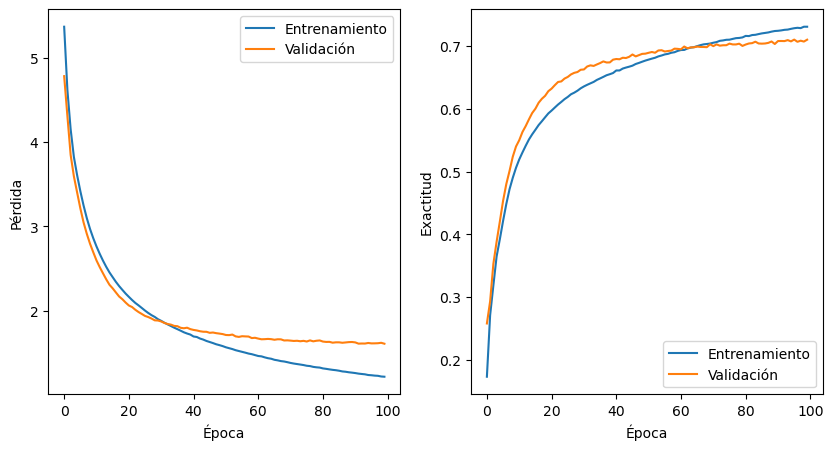

In [30]:
f,axs = plt.subplots(nrows=1, ncols=2, figsize=(10, 5))

axs[0].plot(hist['ent']['perdida'], label='Entrenamiento')
axs[0].plot(hist['val']['perdida'], label='Validación')
axs[0].set_xlabel('Época')
axs[0].set_ylabel('Pérdida')
axs[0].legend()

axs[1].plot(hist['ent']['exactitud'], label='Entrenamiento')
axs[1].plot(hist['val']['exactitud'], label='Validación')
axs[1].set_xlabel('Época')
axs[1].set_ylabel('Exactitud')
axs[1].legend()
plt.show()

Traducimos un lote con el mejor modelo.

In [31]:
traducciones = traduce_greedy(mejor_modelo, src_batch, src_len, vocab)

for i in range(len(traducciones)):
  src_txt = [t for t in convert_indexes(src_batch[:, i], vocab.id2str_fr)
             if t not in {'<PAD>', '<CLS>', '<SEP>'}]
  tgt_txt = [t for t in convert_indexes(tgt_out_batch[:, i], vocab.id2str_en)
             if t not in {'<PAD>', '<CLS>', '<SEP>'}]
  print(f'SRC: {" ".join(src_txt)}\n'
        f'TGT: {" ".join(tgt_txt)}\n'
        f'PRD: {traducciones[i]}\n')

SRC: Une femme brune peint une grande fresque par terre .
TGT: A brunette woman is painting large mural on the ground .
PRD: A brunette woman paints a large mural on the ground .

SRC: Un homme fait un tas de terre à l' aide d' une pelle
TGT: Man shoveling dirt into a pile
PRD: A man is performing a dirt shot to help a shovel

SRC: Une grande foule de personnes , certaines avec les mains en l' air , sont rassemblées dans un grand bâtiment .
TGT: A large crowd of people , some with their hands in the air , gather in a large building .
PRD: A large crowd of people , some with hands in the air , are gathered in a large building .

SRC: Un artiste de rue se reposant sur le perron après une dure journée au bureau .
TGT: Sidewalk artist relaxing on the stoop after a hard day at the office .
PRD: A street performer relaxing on the stoop after a book at the desk .

SRC: Une femme tendant les bras vers des lumières .
TGT: A woman reaching out to lights .
PRD: A woman is putting his arms to ligh

## Evaluación
Vamos a evaluar el traductor entrenado en el subconjunto de prueba, por lo que lo instanciamos y creamos su cargador.

In [32]:
pruds = Multi30k(test_urls[0], test_urls[1], tok_fr, tok_en, vocab)
prudl = DataLoader(pruds,
                   batch_size = BATCH_SIZE,
                   shuffle = False,
                   drop_last = False,
                   collate_fn = PadSequences())

Para hacer una evaluación final de las traducciones generadas usaremos BLEU de `torchmetrics`. BLEU compara los n-gramas (de 1 a 4 palabras) de la traducción generada con los de la traducción de referencia y aplica una penalización si la traducción es más corta que la referencia. Su valor va de 0 a 1 (o de 0 a 100).

In [33]:
def calcula_bleu(modelo: nn.Module,
                 dl: th.utils.data.DataLoader,
                 refs: list[str],
                 disp: str) -> float:
  # traducimos todas las oraciones del cargador
  traducciones = []
  for src, src_len, _, _ in dl:
    src = src.to(disp)

    traducciones.extend(traduce_greedy(modelo, src,  src_len, modelo.vocab))

  # BLEU con n-gramas de hasta orden 4
  # Cada hipótesis tiene una sola referencia
  bleu = torchmetrics.text.BLEUScore(n_gram = 4)
  return bleu(traducciones, [[r] for r in refs]).item()

Evaluamos las traducciones generadas del conjunto de prueba.

In [34]:
refs_pru = [' '.join(t.text for t in tok_en(l.strip()))
            for l in read_sentences(test_urls[1])]

bleu_pru = calcula_bleu(mejor_modelo, prudl, refs_pru, DEVICE)
print(f'BLEU (prueba) = {100 * bleu_pru:.2f}')

BLEU (prueba) = 43.65


Visualizamos la atención de un ejemplo del subconjunto de prueba.

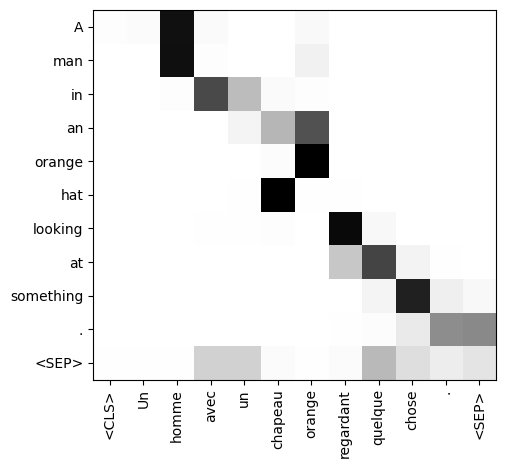

In [35]:
src_pru, src_len_pru, _, _ = next(iter(prudl))

grafica_atencion(mejor_modelo,
                 src_pru[:, 0:1].to(DEVICE),
                 src_len_pru[0:1],
                 vocab)